# Phase 1 — Exploratory Data Analysis
Manual EDA and baseline modeling. Phase 2 (`agents/`) automates the same steps with Strands agents on Bedrock, reusing the `src/` modules called here.

Select the `.venv` kernel in VS Code (top-right of the notebook).

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from src import config, data, eda, modeling

pd.set_option('display.max_columns', 50)
TARGET = config.TARGET_COLUMN
df = data.load_data()
df.head()

Matplotlib is building the font cache; this may take a moment.


,loan_id,credit_score,annual_income,loan_amount,term_months,apr,dti,ltv,employment_years,vehicle_type,region,default
0,1,711.0,48200.0,28600.0,72,3.77,0.147,0.910,4.1,used,West,0
1,2,617.0,47300.0,35100.0,60,9.27,0.258,0.943,2.9,new,Northeast,0
2,3,743.0,39600.0,13700.0,84,3.02,0.201,1.254,7.7,certified,West,0
3,4,756.0,65700.0,24400.0,36,2.24,0.242,0.924,12.6,used,Midwest,0
4,5,553.0,60200.0,34500.0,60,10.57,0.389,0.942,4.4,used,South,0


## 1. Overview

In [2]:
eda.overview(df, TARGET)

{'rows': 5000,
 'columns': 12,
 'dtypes': {'loan_id': 'int64',
  'credit_score': 'float64',
  'annual_income': 'float64',
  'loan_amount': 'float64',
  'term_months': 'int64',
  'apr': 'float64',
  'dti': 'float64',
  'ltv': 'float64',
  'employment_years': 'float64',
  'vehicle_type': 'str',
  'region': 'str',
  'default': 'int64'},
 'duplicate_rows': 0,
 'memory_mb': np.float64(0.94),
 'target': 'default',
 'target_rate': 0.1008,
 'target_counts': {0: 4496, 1: 504}}

## 2. Missing values

In [3]:
eda.missing_report(df)

,missing,pct
employment_years,181,3.62
dti,90,1.80
credit_score,53,1.06


## 3. Numeric summary

In [4]:
eda.numeric_summary(df)

,count,mean,std,min,25%,50%,75%,max,skew
loan_id,5000.0,2500.500,1443.520,1.00,1250.750,2500.500,3750.250,5000.00,0.00
credit_score,4947.0,688.533,69.135,450.00,642.000,690.000,734.000,850.00,-0.07
annual_income,5000.0,60649.640,32113.188,18000.00,40200.000,53800.000,73400.000,552800.00,3.61
loan_amount,5000.0,26942.100,8938.520,5000.00,20900.000,26700.000,33000.000,64400.00,0.12
term_months,5000.0,62.026,13.507,36.00,48.000,60.000,72.000,84.00,-0.32
apr,5000.0,5.636,2.432,1.90,3.800,5.500,7.290,14.52,0.37
dti,4910.0,0.255,0.100,0.03,0.186,0.244,0.313,0.80,0.75
ltv,5000.0,1.019,0.180,0.40,0.902,1.018,1.134,1.60,-0.00
employment_years,4819.0,7.523,4.815,0.10,4.000,6.500,10.000,40.00,1.26
default,5000.0,0.101,0.301,0.00,0.000,0.000,0.000,1.00,2.65


## 4. Categorical features vs. target

In [5]:
import json
print(json.dumps(eda.categorical_summary(df, TARGET), indent=2, default=str))

{
  "vehicle_type": {
    "certified": {
      "count": 717,
      "target_rate": 0.1018
    },
    "new": {
      "count": 2228,
      "target_rate": 0.1005
    },
    "used": {
      "count": 2055,
      "target_rate": 0.1007
    }
  },
  "region": {
    "Midwest": {
      "count": 1015,
      "target_rate": 0.1015
    },
    "Northeast": {
      "count": 780,
      "target_rate": 0.0897
    },
    "South": {
      "count": 1861,
      "target_rate": 0.1085
    },
    "West": {
      "count": 1344,
      "target_rate": 0.096
    }
  }
}


## 5. Outliers (IQR rule)

In [6]:
eda.outlier_report(df, TARGET)

,column,outliers,pct,lower,upper
0,annual_income,176,3.52,-9600.0000,123200.0000
1,employment_years,139,2.88,-5.0000,19.0000
2,dti,87,1.77,-0.0045,0.5035
3,ltv,63,1.26,0.5540,1.4820
4,credit_score,23,0.46,504.0000,872.0000
5,apr,21,0.42,-1.4350,12.5250
6,loan_amount,17,0.34,2750.0000,51150.0000
7,term_months,0,0.00,12.0000,108.0000


## 6. Correlation with target

In [7]:
eda.target_correlations(df, TARGET)

credit_score       -0.269
apr                 0.264
dti                 0.117
loan_amount         0.065
ltv                 0.061
annual_income      -0.051
term_months         0.047
employment_years   -0.043
Name: default, dtype: float64

## 7. Visuals

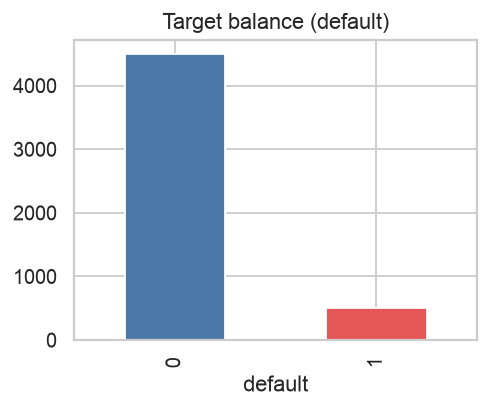

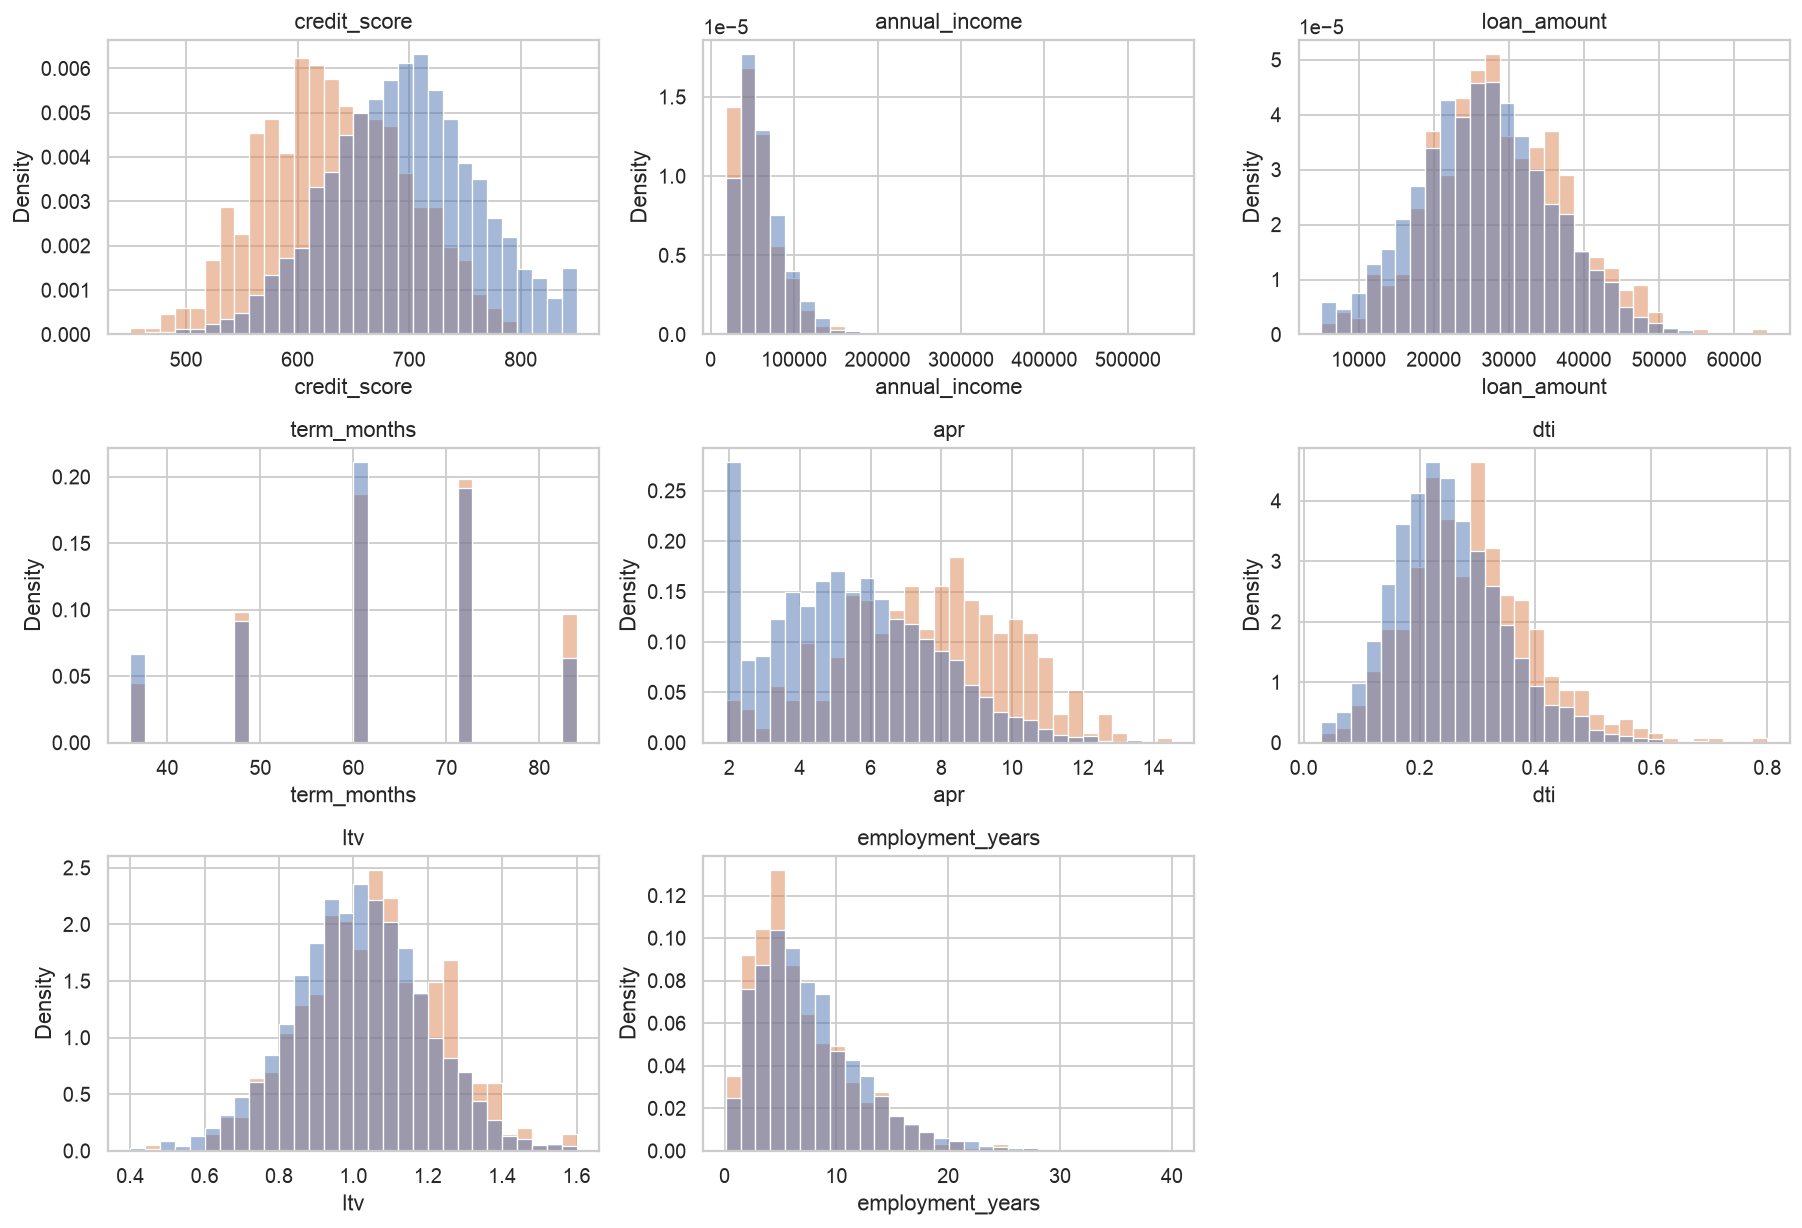

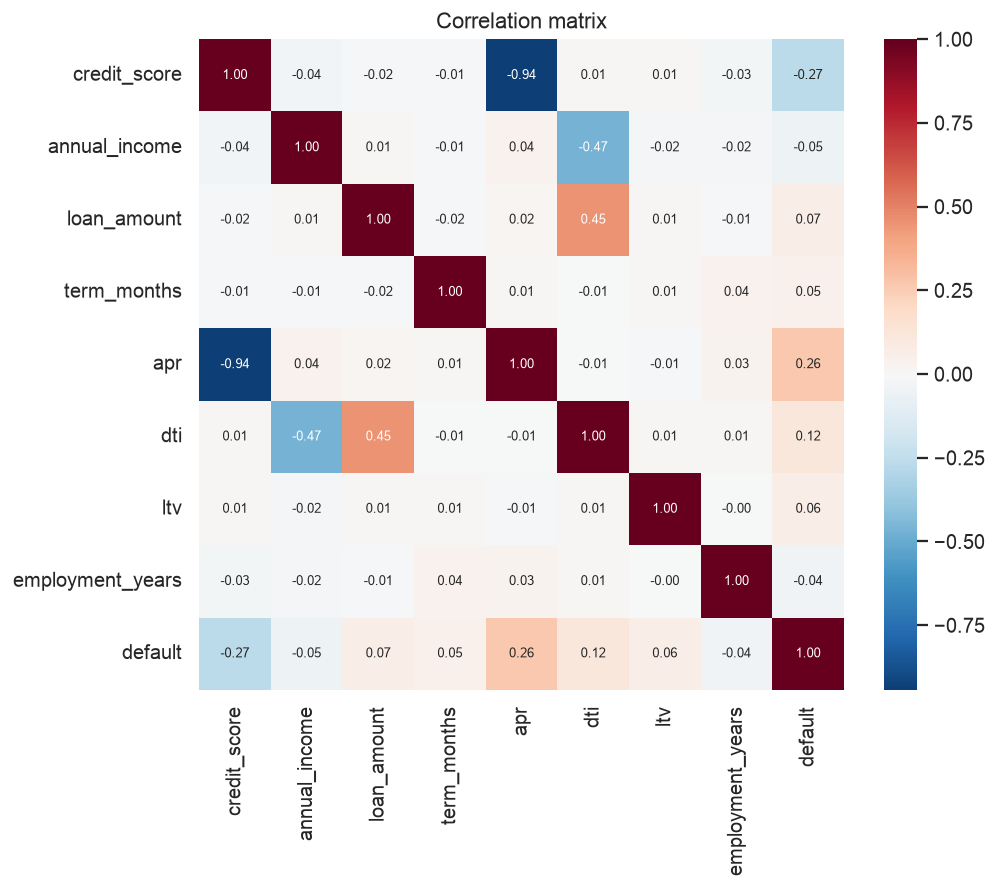

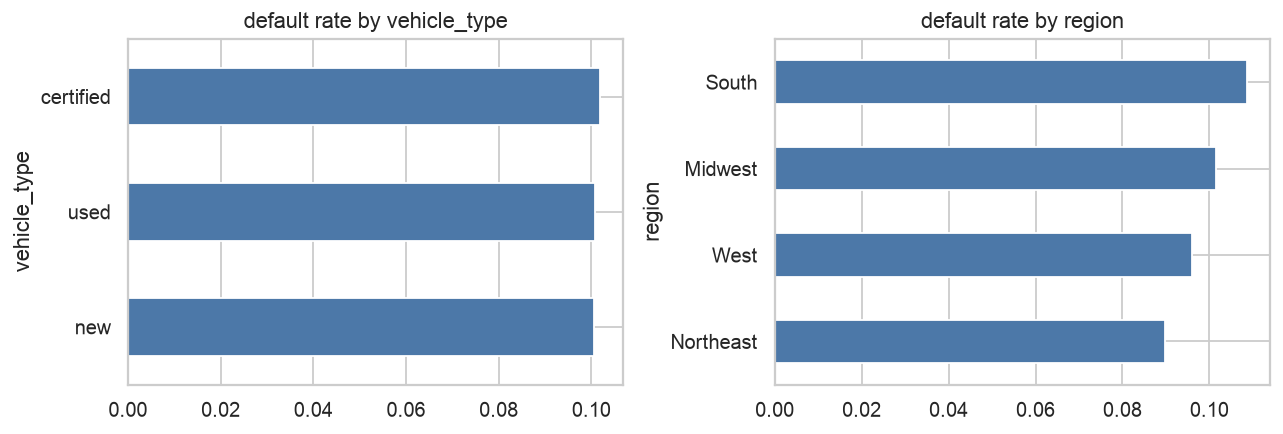

In [8]:
figs = {
    'balance': eda.plot_target_balance(df, TARGET),
    'dist': eda.plot_distributions(df, TARGET),
    'corr': eda.plot_correlation_heatmap(df),
    'cat': eda.plot_target_rate_by_category(df, TARGET),
}
for p in figs.values():
    display(Image(p))

## 8. EDA takeaways
_Edit these after reviewing the output above._

- Class imbalance: _?_
- Data quality (missingness, outliers): _?_
- Strongest predictors: _?_
- Planned preprocessing: median impute + scale numerics, one-hot categoricals; consider capping income outliers.

## 9. Baseline modeling & evaluation

In [9]:
cmp = modeling.compare_models(df, TARGET)
pd.DataFrame(cmp['results']).T.drop(columns='confusion')

,roc_auc,pr_auc,gini,ks,brier,accuracy,precision,recall,f1,threshold,cv_auc_mean,cv_auc_std
logistic_regression,0.7747,0.2939,0.5494,0.4436,0.1938,0.7056,0.2173,0.7381,0.3357,0.5,0.7678,0.0298
random_forest,0.7629,0.2918,0.5258,0.4293,0.1342,0.8168,0.2771,0.5079,0.3585,0.5,0.748,0.0323
gradient_boosting,0.7624,0.2529,0.5247,0.4587,0.0857,0.8896,0.3,0.0714,0.1154,0.5,0.7415,0.0337


Best model: logistic_regression


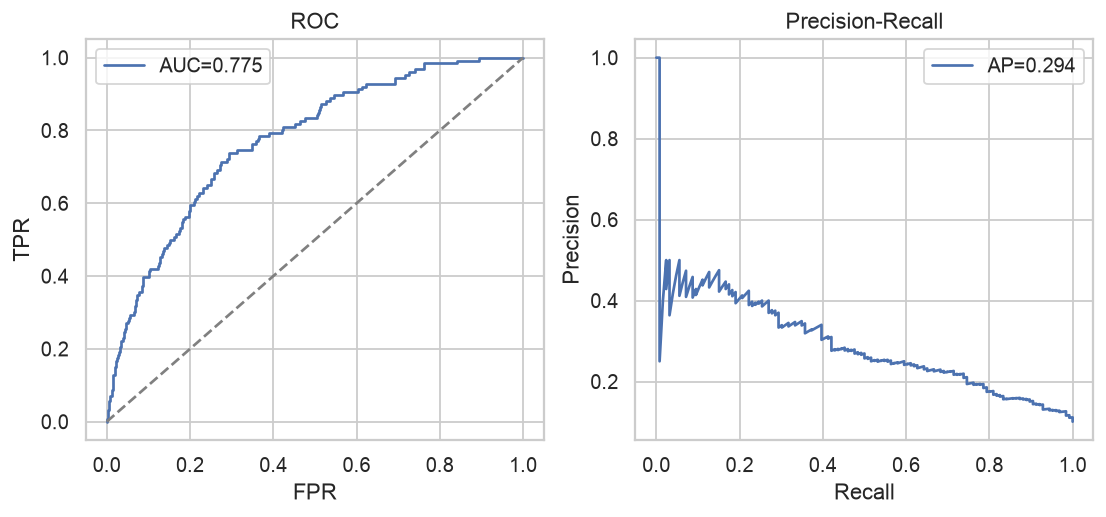

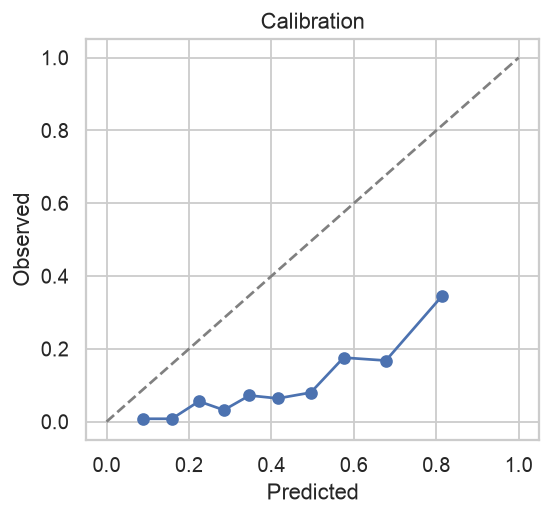

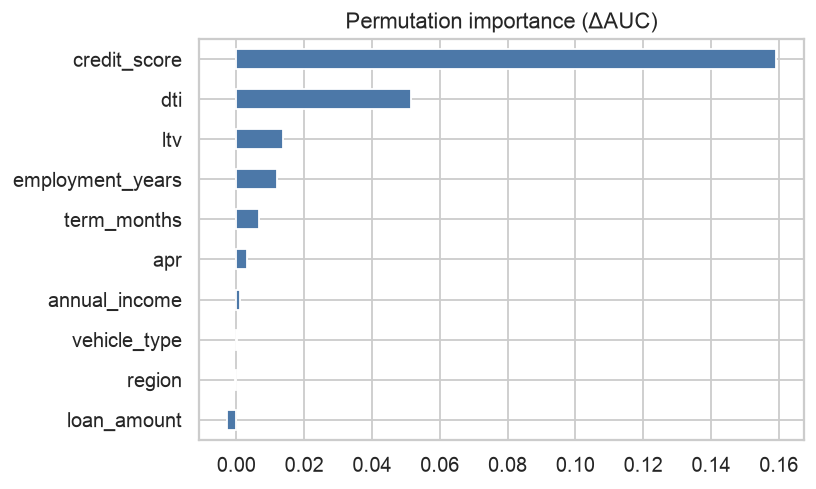

In [10]:
best = cmp['best']
X_tr, X_te, y_tr, y_te = cmp['split']
plots = modeling.evaluation_plots(cmp['fitted'][best], X_te, y_te, best)
print('Best model:', best)
for k in ('roc_pr', 'calibration', 'importance'):
    display(Image(plots[k]))

In [11]:
# Segment fairness / stability check
for col in ['vehicle_type', 'region']:
    if col in X_te.columns:
        display(modeling.segment_performance(cmp['fitted'][best], X_te, y_te, col))

,vehicle_type,n,actual_rate,mean_pred,auc
0,certified,173,0.1156,0.4148,0.8216
1,new,554,0.1011,0.4134,0.7550
2,used,523,0.0956,0.4001,0.7777


,region,n,actual_rate,mean_pred,auc
0,Midwest,276,0.1014,0.3968,0.7939
1,Northeast,188,0.1170,0.3705,0.7549
2,South,455,0.1011,0.4350,0.7665
3,West,331,0.0906,0.4018,0.7900
